## MTL Trajet: 25 Single User Long Term Mobility Change (Flag 25)

### Dataset Overview

Eight weeks of trajectories for one Montréal user, with work, shopping, and leisure purpose, day type, destination, route family, mode, point speed, and weekly spatial metrics.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Explore long-term mobility patterns and changes in individual travel behavior of the user.

Role: Urban mobility-pattern analyst


Category: Eight weeks of trajectories for one Montréal user, with work, shopping, and leisure purpose, day type, destination, route family, mode, point speed, and weekly spatial metrics.

Distances and directness are calculated from delivered GPS polylines; point speeds, trip durations, chain timing, and paired-leg timing are synchronized with the supplied point table. Route directness ratio is route distance divided by straight-line distance, so it is at least 1 and lower values indicate more direct routes.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How stable are work departure time, mode, destination, route family, and speed profile?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

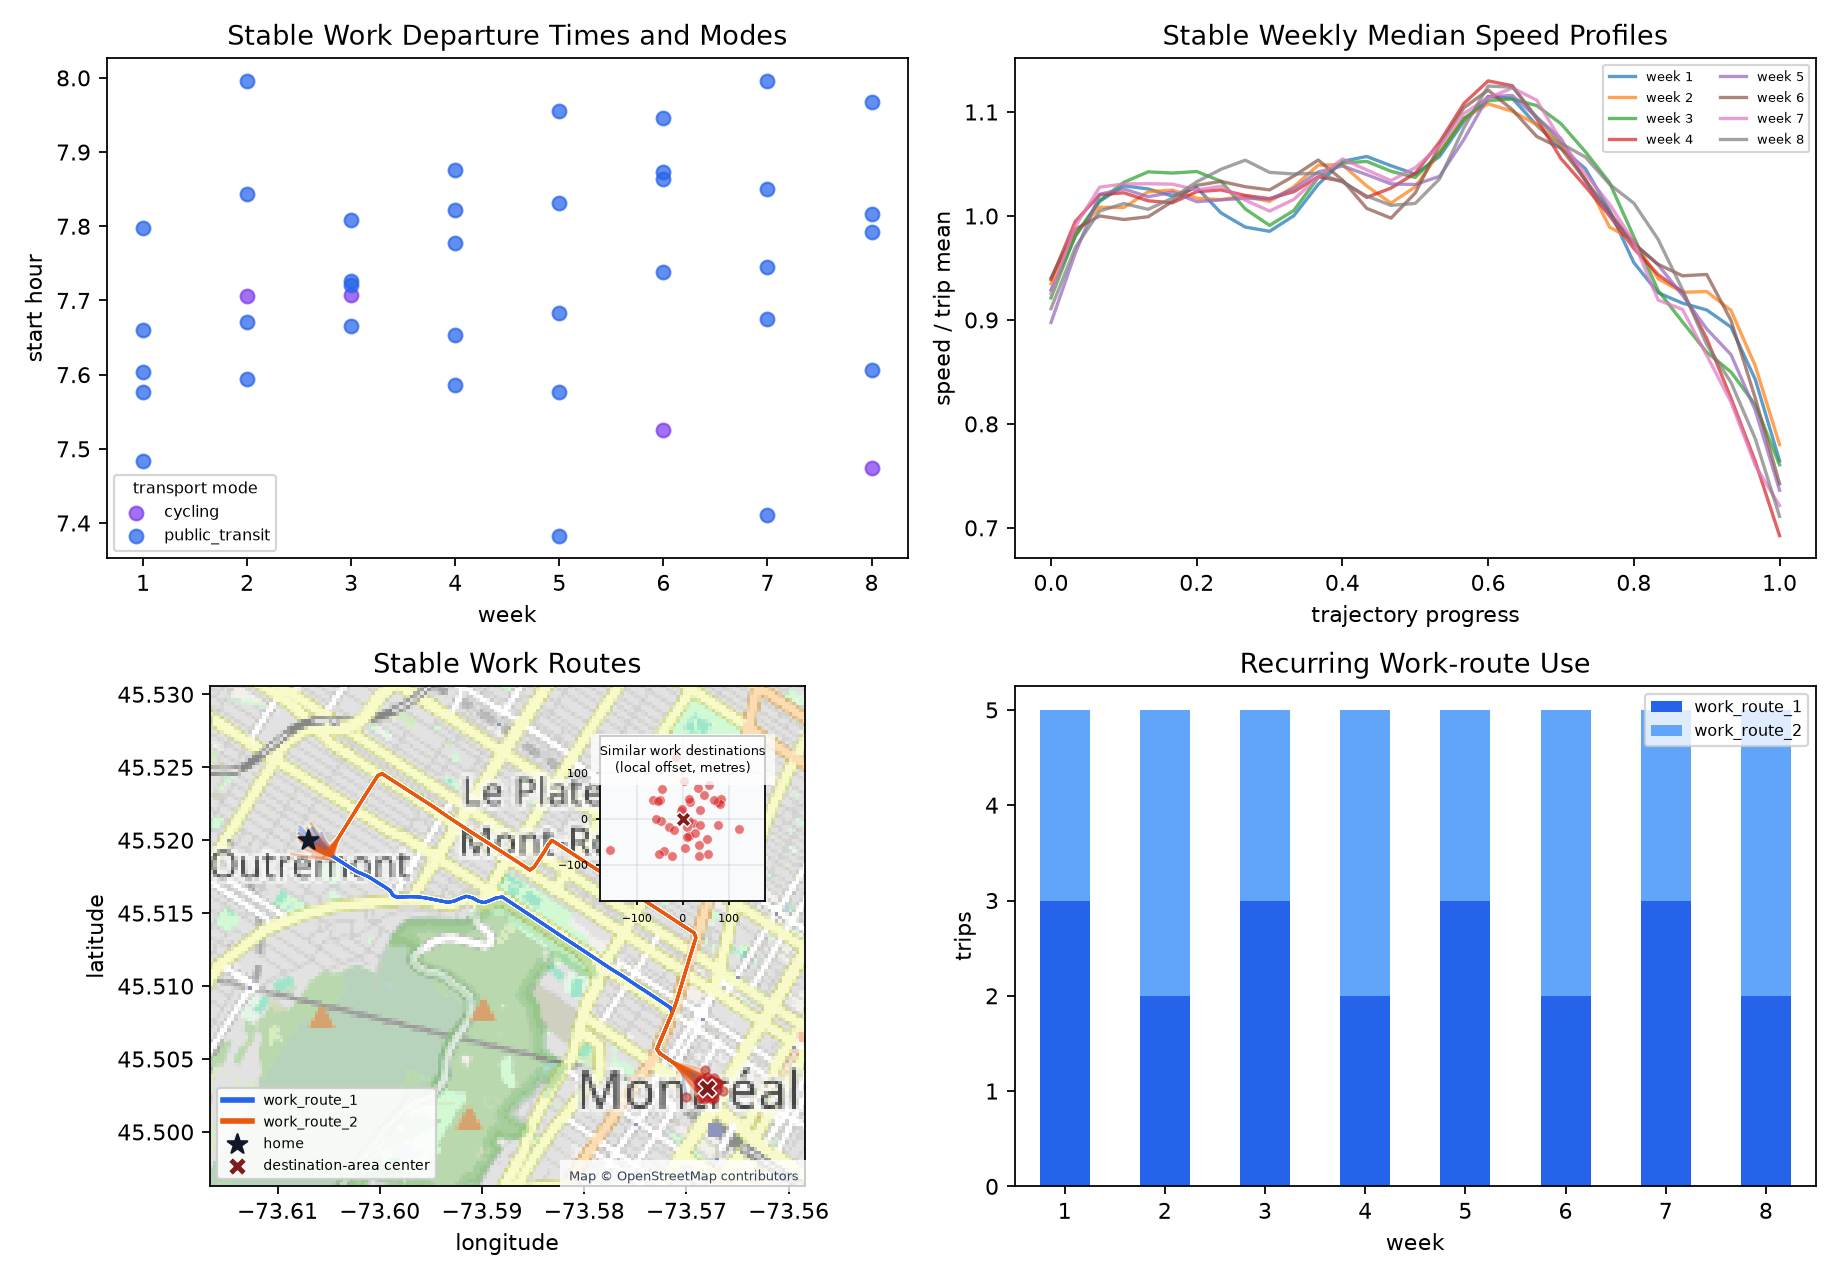

In [ ]:
df[df.purpose_group.eq("work")].groupby("week_index").agg(
    start_median=("start_hour", "median"),
    start_std=("start_hour", "std"),
    modes=("mode_group", "nunique"),
    destinations=("destination_zone", "nunique"),
    routes=("route_family", "nunique"),
)
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/weekly_work_stability.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "weekly_work_stability",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Work-trip Stability across Weeks",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/weekly_work_stability.png"
  },
  "question": "How stable are work departure time, mode, destination, route family, and speed profile?",
  "code": "df[df.purpose_group.eq('work')].groupby('week_index').agg(start_median=('start_hour','median'),start_std=('start_hour','std'),modes=('mode_group','nunique'),destinations=('destination_zone','nunique'),routes=('route_family','nunique'))",
  "insight": "Across weeks, work trips retain similar departure times, modes, destination areas, recurring routes, and characteristic speed profiles.",
  "insight_type": "overall_pattern",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "trajectory_id",
    "trip_purpose",
    "transport_mode",
    "gps_position",
    "point_speed"
  ]
}

### **Question 2**: Do shopping and leisure trips shift later, farther, and toward more varied destinations and modes?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

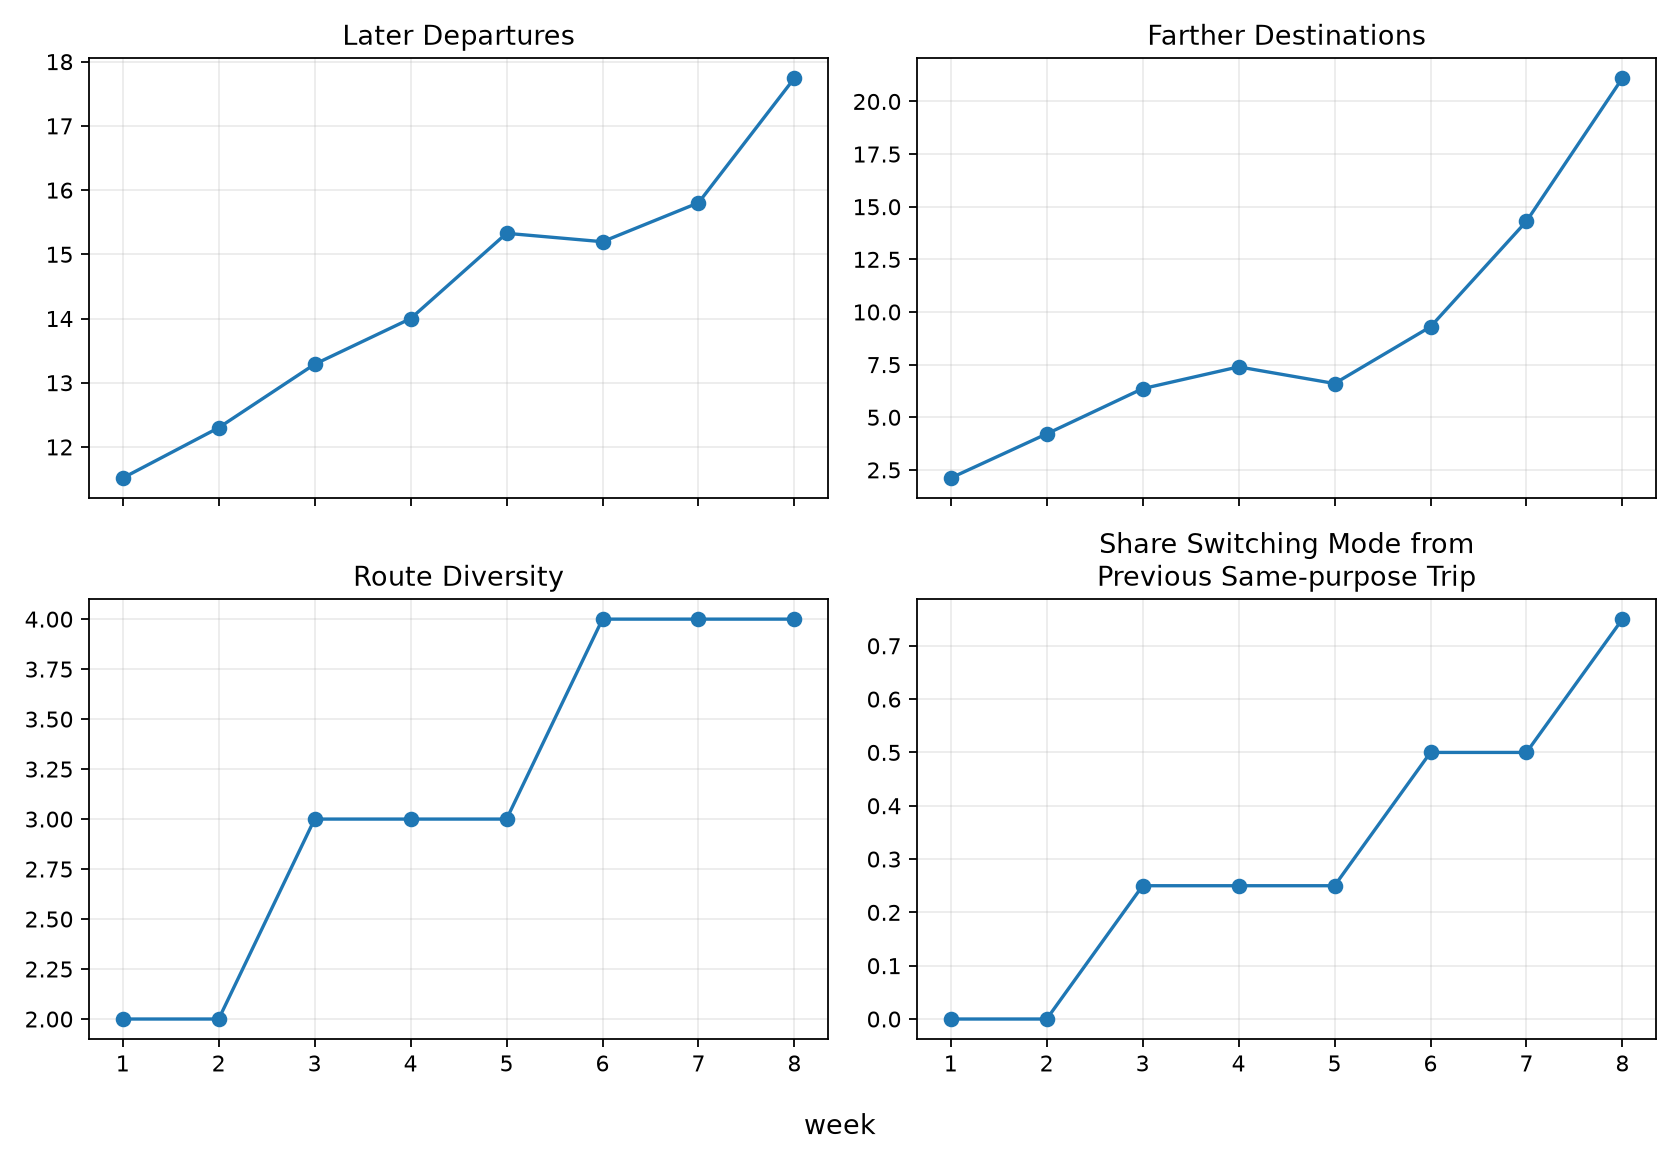

In [ ]:
q = df[df.purpose_group.isin(["shopping", "leisure"])]
q.groupby("week_index").agg(
    start=("start_hour", "median"),
    distance=("distance_km", "median"),
    destinations=("destination_zone", "nunique"),
    mode_change=("mode_changed_from_previous_purpose_trip", "mean"),
)
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/discretionary_weekly_shift.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "discretionary_weekly_shift",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Shopping and Leisure Change across Weeks",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/discretionary_weekly_shift.png"
  },
  "question": "Do shopping and leisure trips shift later, farther, and toward more varied destinations and modes?",
  "code": "q=df[df.purpose_group.isin(['shopping','leisure'])]; q.groupby('week_index').agg(start=('start_hour','median'),distance=('distance_km','median'),destinations=('destination_zone','nunique'),mode_change=('mode_changed_from_previous_purpose_trip','mean'))",
  "insight": "Shopping and leisure trips gradually shift toward later departures and farther destinations, with greater route diversity and more frequent mode changes.",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "trajectory_id",
    "trip_purpose",
    "transport_mode",
    "gps_position"
  ]
}

### **Question 3**: For similar-purpose trips, how are farther destinations associated with mode, cruising speed, and route directness?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

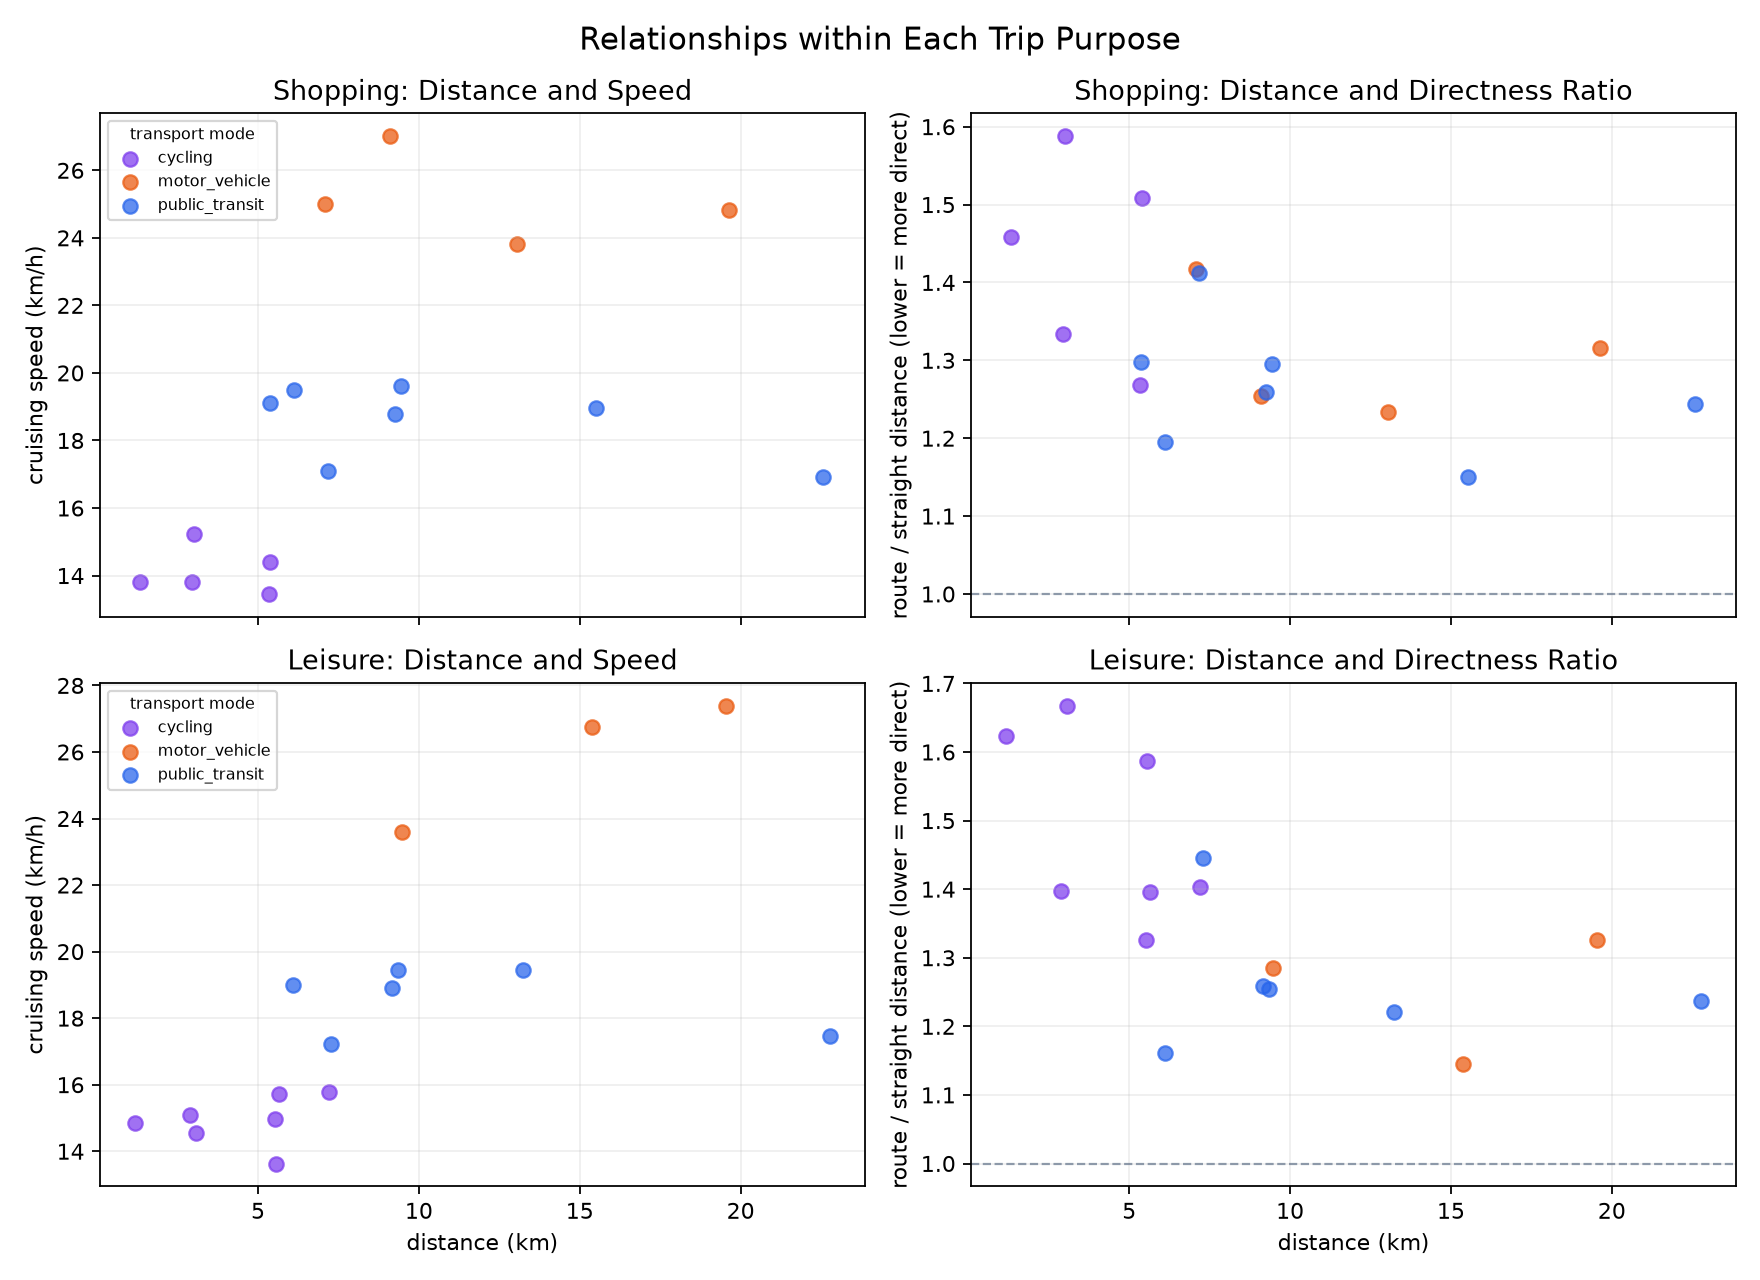

In [ ]:
df[df.purpose_group.isin(["shopping", "leisure"])].groupby(
    ["purpose_group", "mode_group"]
)[["distance_km", "cruising_speed_kmh", "route_directness"]].median()
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/distance_mode_speed_directness.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "distance_mode_speed_directness",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Distance, Mode, Speed, and Directness",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/distance_mode_speed_directness.png"
  },
  "question": "For similar-purpose trips, how are farther destinations associated with mode, cruising speed, and route directness?",
  "code": "df[df.purpose_group.isin(['shopping','leisure'])].groupby(['purpose_group','mode_group'])[['distance_km','cruising_speed_kmh','route_directness']].median()",
  "insight": "When similar-purpose trips extend to farther destinations, the user adopts faster modes, reaches higher cruising speeds, and follows more direct routes.",
  "insight_type": "factor_relationship",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "transport_mode",
    "gps_position",
    "point_speed",
    "trajectory_id"
  ]
}

### **Question 4**: How do weekend and weekday destination footprints change over successive weeks?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

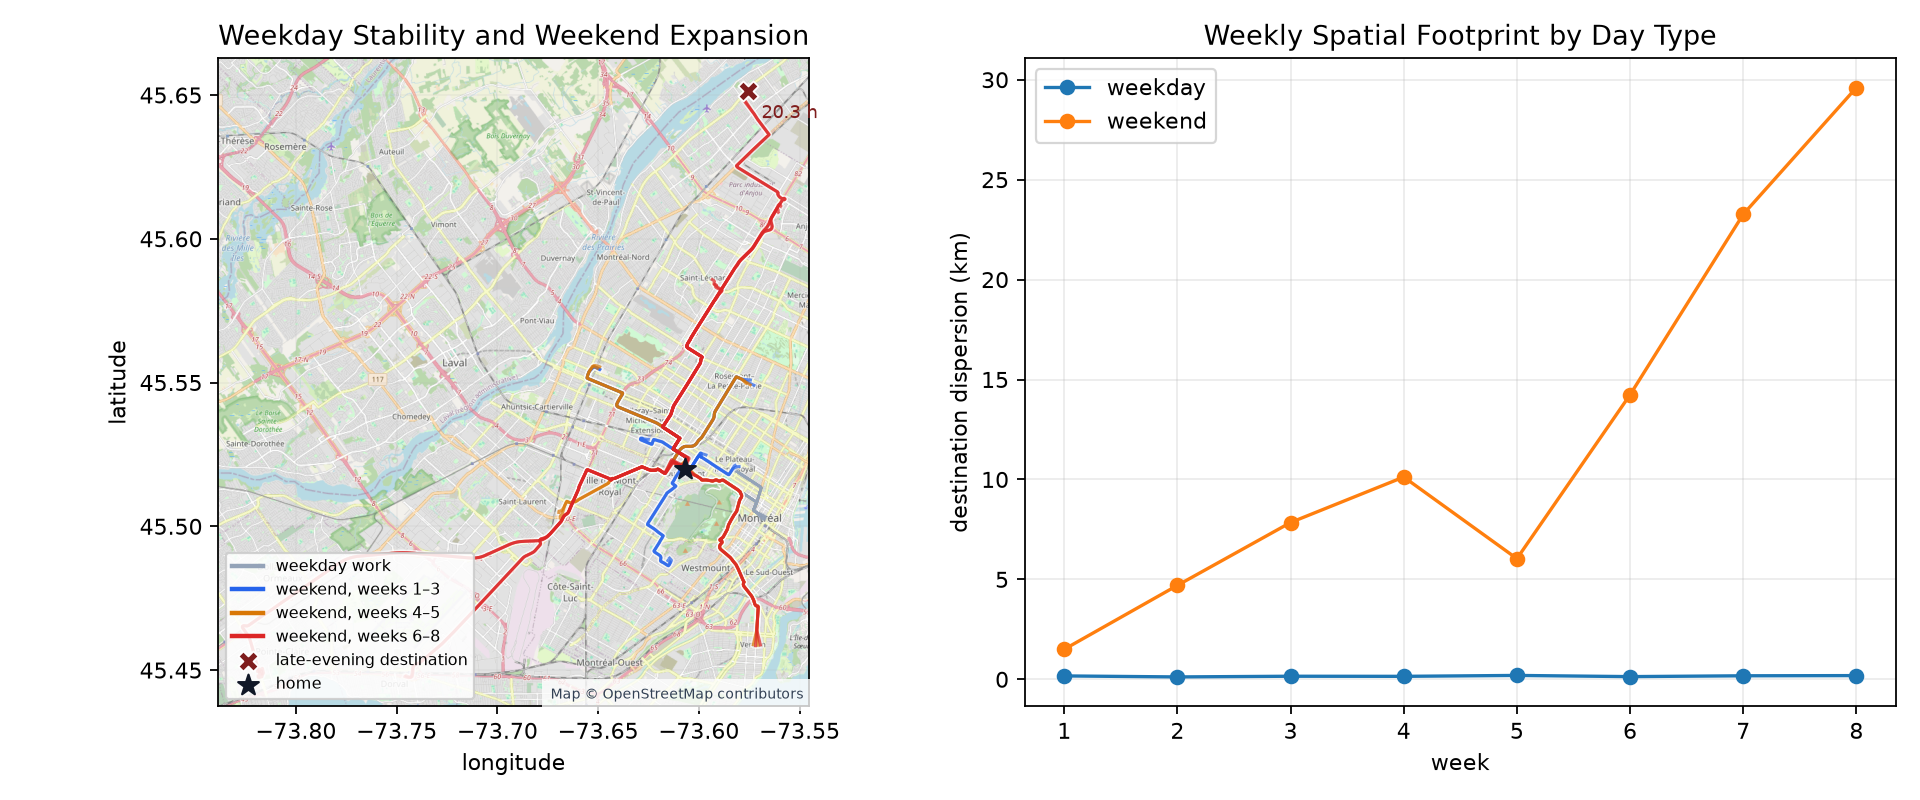

In [ ]:
df.groupby(
    ["week_index", "day_type"]
).first().weekly_destination_dispersion_km.unstack()
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/weekend_weekday_spatial_extent.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "weekly_spatial_extent",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Weekend and Weekday Spatial Extent",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/weekend_weekday_spatial_extent.png"
  },
  "question": "How do weekend and weekday destination footprints change over successive weeks?",
  "code": "df.groupby(['week_index','day_type']).first().weekly_destination_dispersion_km.unstack()",
  "insight": "Weekend travel becomes spatially broader over later weeks, while weekday trips remain concentrated around a small set of locations.",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "trajectory_id",
    "gps_position",
    "trip_purpose"
  ]
}

### Summary of Findings (Flag 25)

The single user's work routine remains stable across eight weeks. Shopping and leisure gradually become later, farther, more spatially diverse, and more multimodal; farther trips use faster modes and more direct routes, expanding the weekend footprint while weekday travel stays concentrated.